# Reproduce paper figures

Regenerates **Figure 1–6** of the manuscript from the derived summary files in `../data/`.
No GPU, model checkpoints, or network access are required — every figure is a function of
the ground-truth JSON/CSV files documented in `../data/DATA_MANIFEST.md`.

Run top to bottom. Figures are written to `../figures/` as 300-dpi PNGs.

- **Fig 1** — no single molecular encoder dominates (within-seed solo test norm_score)
- **Fig 2** — representation-level joint fusion (MAP) raises the floor but rarely tops the best single model
- **Fig 3** — ensemble-size sweep: diminishing marginal gain, elbow at k=5
- **Fig 4** — validation→test reliability of subset selection (post-hoc)
- **Fig 5** — per-member Leave-One-Out and Shapley contributions in the final k=5 ensemble
- **Fig 6** — external validation: LateFusion-k5 on the official Polaris ADME-Fang leaderboards


In [1]:
import json, os
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DATA = "../data"
OUT  = "../figures"
os.makedirs(OUT, exist_ok=True)

def load_json(fn):
    with open(os.path.join(DATA, fn)) as f: return json.load(f)
def load_csv(fn):
    return pd.read_csv(os.path.join(DATA, fn))

# ---- self-contained publication style (no external skill dependency) ----
def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 300,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
        "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 9,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
        "figure.autolayout": False, "savefig.bbox": "tight",
    })
apply_style()

# consistent colours: red = member of the final k=5 ensemble, grey = not
FINAL5 = set(["mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_graphmvp","stl_map"])
MLABEL = {"mtl_dmpnn":"D-MPNN\u00b7MTL","mtl_molformer":"MoLFormer\u00b7MTL",
          "mtl_chemeleon":"CheMeleon\u00b7MTL","mtl_graphmvp":"GraphMVP\u00b7MTL","mtl_map":"MAP\u00b7MTL",
          "stl_dmpnn":"D-MPNN\u00b7STL","stl_molformer":"MoLFormer\u00b7STL",
          "stl_chemeleon":"CheMeleon\u00b7STL","stl_graphmvp":"GraphMVP\u00b7STL","stl_map":"MAP\u00b7STL"}
RED, GREY, DARK = "#c0392b", "#aab7c0", "#2c3e50"
print("data files:", sorted(os.listdir(DATA)))


data files: ['DATA_MANIFEST.md', 'additions.json', 'all1023.csv', 'ground_truth.json', 'pertask.json', 'polaris_all_model_test_preds.csv', 'polaris_ensemble_pertask_val_pearson.csv', 'polaris_leaderboard_full.json', 'polaris_official_overall.csv', 'polaris_official_pertask_pearson.csv', 'polaris_official_submitted_rank.csv', 'reconciliation_flags.json', 'solo10_within_cross.json', 'stat_tests.json', 'tables_data.json', 'uniform_val_test_unified.csv']


## Figure 1 — No single molecular encoder dominates

Within-seed (matched-seed) solo held-out-test norm_score for all 10 backbone×regime models,
across the 21 valid TDC ADMET tasks. Ranked; red bars are the models that end up in the
final k=5 late-fusion ensemble.

best single (within): CheMeleon·STL 0.6331


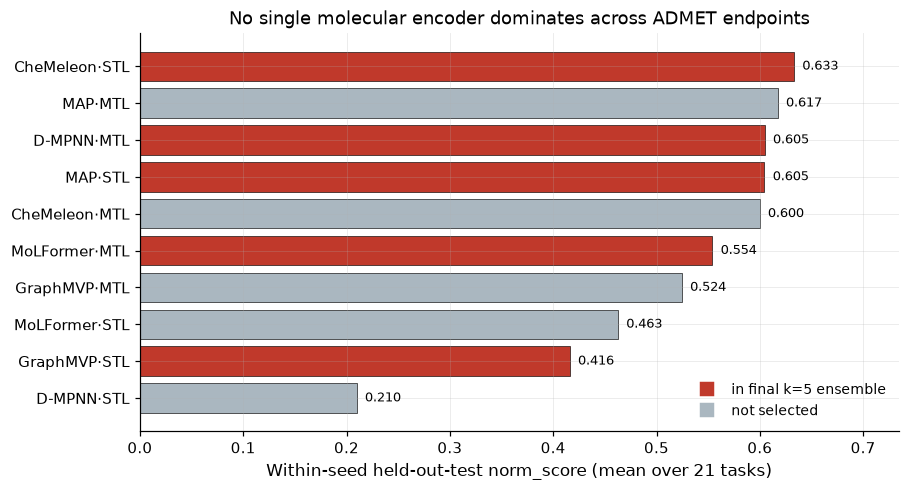

In [2]:
gt = load_json("ground_truth.json")
solo = gt["per_model_within_cross_solo"]          # {model:[within,cross]}
rows = sorted(solo.items(), key=lambda kv: -kv[1][0])   # by within-seed
names  = [MLABEL[m] for m,_ in rows]
vals   = [v[0] for _,v in rows]
colors = [RED if m in FINAL5 else GREY for m,_ in rows]

fig, ax = plt.subplots(figsize=(8.4, 4.6))
y = np.arange(len(rows))[::-1]
ax.barh(y, vals, color=colors, edgecolor="black", linewidth=0.4)
for yi, v in zip(y, vals):
    ax.text(v+0.008, yi, f"{v:.3f}", va="center", ha="left", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(names)
ax.set_xlabel("Within-seed held-out-test norm_score (mean over 21 tasks)")
ax.set_title("No single molecular encoder dominates across ADMET endpoints")
ax.set_xlim(0, max(vals)*1.16)
leg = [Line2D([0],[0],marker="s",color="w",markerfacecolor=RED,markersize=10,label="in final k=5 ensemble"),
       Line2D([0],[0],marker="s",color="w",markerfacecolor=GREY,markersize=10,label="not selected")]
ax.legend(handles=leg, frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(f"{OUT}/figure1.png"); plt.show()
print("best single (within):", names[0], vals[0])

## Figure 2 — Representation-level joint fusion (MAP): raises the floor, rarely tops the best single

Modality Attention Pooling (MAP) is compared against latent **mean** and **max** aggregation.
Panel (a): mean 21-task norm_score. Panel (b): number of tasks (of 21) where MAP beats the
mean-aggregation baseline vs. where it beats the per-task best single backbone.

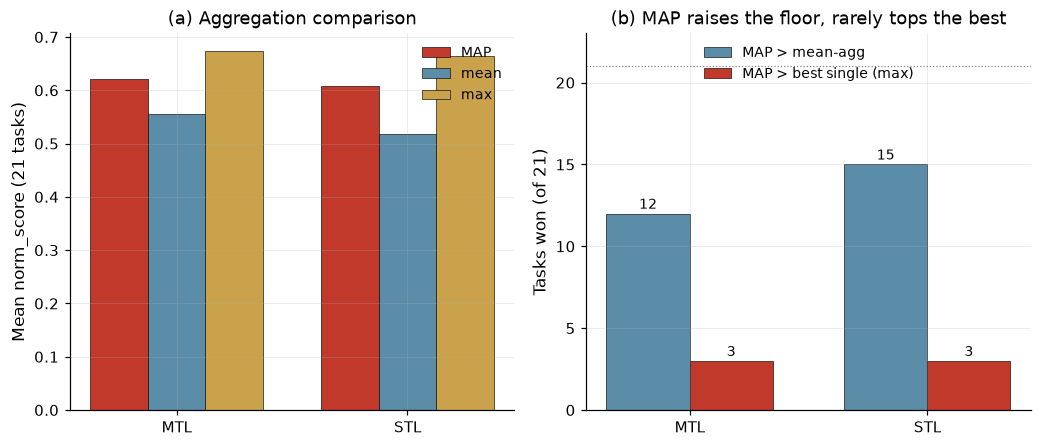

In [3]:
magg = gt["map_agg"]        # {'mtl':{...}, 'stl':{...}}
fig, (axA, axB) = plt.subplots(1, 2, figsize=(9.6, 4.2))

# (a) mean norm_score for map / mean / max, MTL & STL
groups = ["mtl","stl"]; aggs=["map","mean","max"]
x = np.arange(len(groups)); w=0.25
aggcol={"map":RED,"mean":"#5b8ca8","max":"#c9a24b"}
for i,a in enumerate(aggs):
    axA.bar(x+(i-1)*w, [magg[g][a] for g in groups], w, label=a.upper() if a=="map" else a,
            color=aggcol[a], edgecolor="black", linewidth=0.4)
axA.set_xticks(x); axA.set_xticklabels(["MTL","STL"])
axA.set_ylabel("Mean norm_score (21 tasks)"); axA.set_title("(a) Aggregation comparison")
axA.legend(frameon=False)

# (b) win-counts: MAP > mean vs MAP > per-task-best
labels=["MTL","STL"]
mgt_mean=[int(magg[g]["map_gt_mean"].split("/")[0]) for g in groups]
mgt_max =[int(magg[g]["map_gt_max"].split("/")[0])  for g in groups]
x2=np.arange(len(labels)); w2=0.35
axB.bar(x2-w2/2, mgt_mean, w2, label="MAP > mean-agg", color="#5b8ca8", edgecolor="black", linewidth=0.4)
axB.bar(x2+w2/2, mgt_max,  w2, label="MAP > best single (max)", color=RED, edgecolor="black", linewidth=0.4)
axB.axhline(21, ls=":", color="grey", lw=0.8)
for xx,v in zip(x2-w2/2, mgt_mean): axB.text(xx,v+0.3,str(v),ha="center",fontsize=9)
for xx,v in zip(x2+w2/2, mgt_max):  axB.text(xx,v+0.3,str(v),ha="center",fontsize=9)
axB.set_xticks(x2); axB.set_xticklabels(labels); axB.set_ylim(0,23)
axB.set_ylabel("Tasks won (of 21)"); axB.set_title("(b) MAP raises the floor, rarely tops the best")
axB.legend(frameon=False, loc="upper center")
fig.tight_layout(); fig.savefig(f"{OUT}/figure2.png"); plt.show()

## Figure 3 — Ensemble-size sweep

Mean of the top-20 subsets at each ensemble size *k* (within-seed and cross-seed tracks).
Panel (b) plots the **combined** (within + cross) marginal gain Δ from *k*−1 to *k* against
ε = 0.01. The combined gain is the last value above ε at the k=4→5 step (+0.0104) and drops
below ε at k=5→6 (+0.0029), placing the elbow — and hence the chosen ensemble size — at **k=5**.

combined marg k4->5: 0.0104 (>eps)  | k5->6: 0.0029 (<eps)


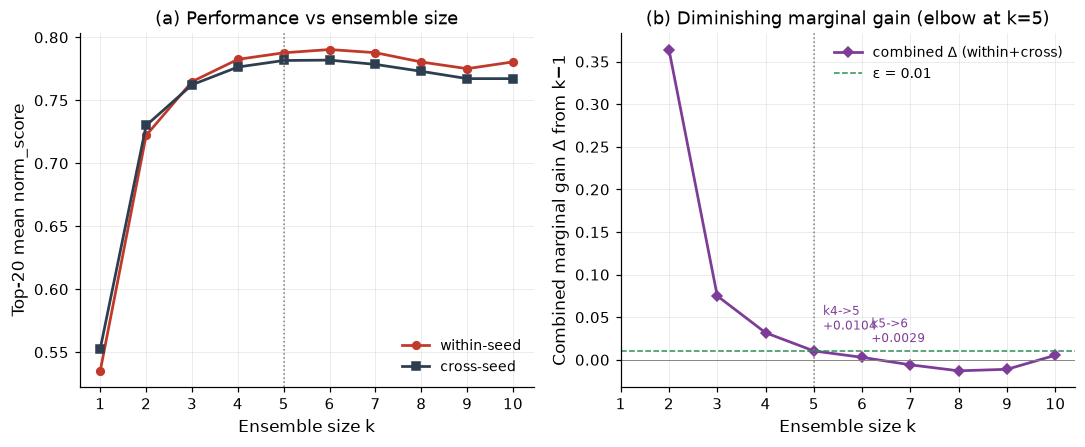

In [4]:
ksweep = gt["ksweep"]   # rows: [k, within_top20, within_marg, cross_top20, cross_marg]
ks   = [r[0] for r in ksweep]
win  = [r[1] for r in ksweep]
cro  = [r[3] for r in ksweep]
# combined marginal = within Δ + cross Δ (the manuscript's basis for the k=5 elbow)
comb_marg = [(r[2]+r[4]) if (r[2] is not None and r[4] is not None) else np.nan for r in ksweep]

fig, (axA, axB) = plt.subplots(1, 2, figsize=(10, 4.2))
axA.plot(ks, win, "-o", color=RED, label="within-seed", lw=1.8, ms=5)
axA.plot(ks, cro, "-s", color=DARK, label="cross-seed", lw=1.8, ms=5)
axA.axvline(5, ls=":", color="grey", lw=1.0)
axA.set_xlabel("Ensemble size k"); axA.set_ylabel("Top-20 mean norm_score")
axA.set_title("(a) Performance vs ensemble size"); axA.legend(frameon=False)
axA.set_xticks(ks)

axB.plot(ks, comb_marg, "-D", color="#7d3c98", label="combined Δ (within+cross)", lw=1.8, ms=5)
axB.axhline(0.01, ls="--", color="#2e8b57", lw=1.0, label="ε = 0.01")
axB.axhline(0.0, ls="-", color="grey", lw=0.6)
axB.axvline(5, ls=":", color="grey", lw=1.0)
# annotate the two decisive steps
axB.annotate(f"k4->5\n+{comb_marg[4]:.4f}", (5, comb_marg[4]), textcoords="offset points",
             xytext=(6,14), fontsize=8, color="#7d3c98")
axB.annotate(f"k5->6\n+{comb_marg[5]:.4f}", (6, comb_marg[5]), textcoords="offset points",
             xytext=(6,10), fontsize=8, color="#7d3c98")
axB.set_xlabel("Ensemble size k"); axB.set_ylabel("Combined marginal gain Δ from k−1")
axB.set_title("(b) Diminishing marginal gain (elbow at k=5)"); axB.legend(frameon=False)
axB.set_xticks(ks)
fig.tight_layout(); fig.savefig(f"{OUT}/figure3.png"); plt.show()
print("combined marg k4->5:", round(comb_marg[4],4), "(>eps)  | k5->6:", round(comb_marg[5],4), "(<eps)")

## Figure 4 — Validation→test reliability of subset selection (post-hoc)

Across all 1,023 non-empty subsets of the 10 base models, the nested-OOF **validation**
norm_score (used for selection) is plotted against the held-out **test** norm_score
(revealed only post-hoc). A strong monotone relationship means validation-only selection
is reliable. The final k=5 configuration is marked.

n subsets: 1023 | combined ρ: 0.805


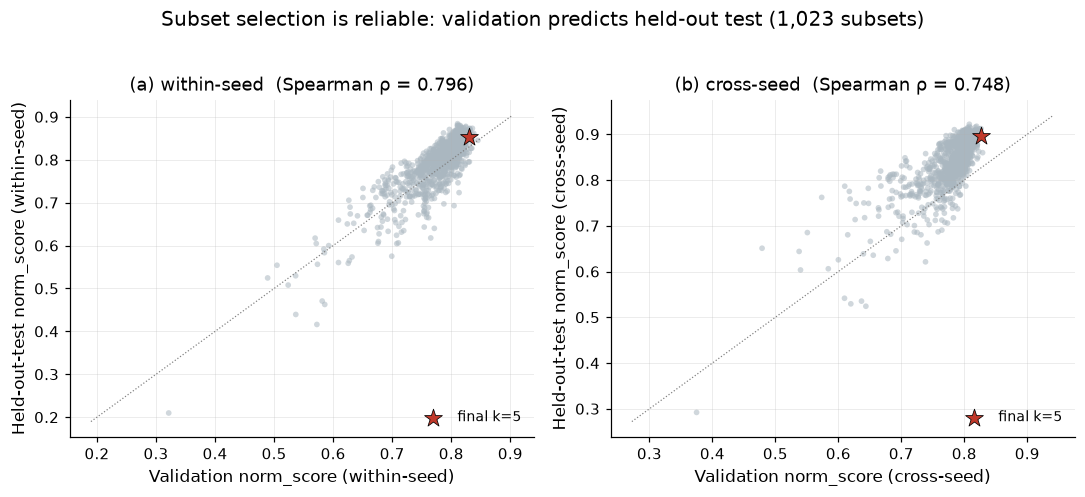

In [5]:
all1023 = load_csv("all1023.csv")
vtc = gt["val_test_corr"]
final_key = ",".join(sorted(gt["final_ensemble"]))

fig, (axA, axB) = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, track, rho in [(axA,"within",vtc["within"]["rho"]), (axB,"cross",vtc["cross"]["rho"])]:
    vx = all1023[f"val_{track}"]; ty = all1023[f"test_{track}"]
    ax.scatter(vx, ty, s=14, color=GREY, alpha=0.55, edgecolor="none")
    # final k=5 point
    row = all1023[all1023["combo_key"].apply(lambda s: ",".join(sorted(s.split(","))))==final_key]
    if len(row):
        ax.scatter(row[f"val_{track}"], row[f"test_{track}"], s=150, marker="*",
                   color=RED, edgecolor="black", lw=0.5, zorder=5, label="final k=5")
    lims=[min(vx.min(),ty.min())-0.02, max(vx.max(),ty.max())+0.02]
    ax.plot(lims, lims, ls=":", color="grey", lw=0.8)
    ax.set_xlabel(f"Validation norm_score ({track}-seed)")
    ax.set_ylabel(f"Held-out-test norm_score ({track}-seed)")
    ax.set_title(f"({'a' if track=='within' else 'b'}) {track}-seed  (Spearman ρ = {rho:.3f})")
    ax.legend(frameon=False, loc="lower right")
fig.suptitle("Subset selection is reliable: validation predicts held-out test (1,023 subsets)", y=1.02)
fig.tight_layout(); fig.savefig(f"{OUT}/figure4.png"); plt.show()
print("n subsets:", len(all1023), "| combined ρ:", vtc["combined"]["rho"])

## Figure 5 — Per-member contribution in the final k=5 ensemble

For each of the five members, the Leave-One-Out effect (Δnorm_score when the member is
removed; positive = removal hurts) and the Shapley value (mean marginal contribution over
all coalitions), on both within-seed and cross-seed tracks.

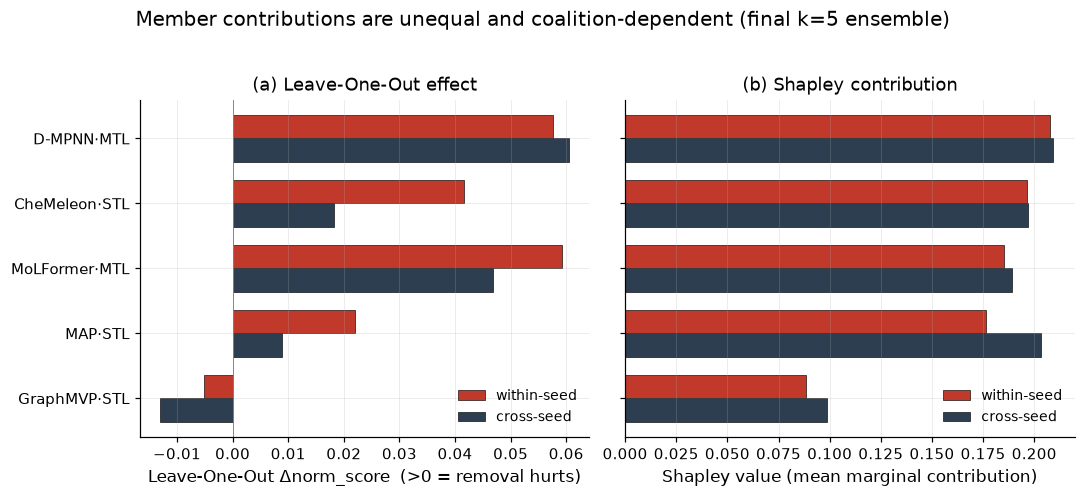

In [6]:
ls = gt["loo_shapley"]   # {model:[within_solo, LOO_within, cross_solo, LOO_cross, Shap_within, Shap_cross]}
members = gt["final_ensemble"]
members = sorted(members, key=lambda m: -ls[m][4])   # by within Shapley
labels  = [MLABEL[m] for m in members]

fig, (axA, axB) = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
y = np.arange(len(members))[::-1]; h=0.36
# (a) LOO
axA.barh(y+h/2, [ls[m][1] for m in members], h, color=RED,  edgecolor="black", lw=0.4, label="within-seed")
axA.barh(y-h/2, [ls[m][3] for m in members], h, color=DARK, edgecolor="black", lw=0.4, label="cross-seed")
axA.axvline(0, color="grey", lw=0.6)
axA.set_yticks(y); axA.set_yticklabels(labels)
axA.set_xlabel("Leave-One-Out Δnorm_score  (>0 = removal hurts)")
axA.set_title("(a) Leave-One-Out effect"); axA.legend(frameon=False, loc="lower right")
# (b) Shapley
axB.barh(y+h/2, [ls[m][4] for m in members], h, color=RED,  edgecolor="black", lw=0.4, label="within-seed")
axB.barh(y-h/2, [ls[m][5] for m in members], h, color=DARK, edgecolor="black", lw=0.4, label="cross-seed")
axB.set_xlabel("Shapley value (mean marginal contribution)")
axB.set_title("(b) Shapley contribution"); axB.legend(frameon=False, loc="lower right")
fig.suptitle("Member contributions are unequal and coalition-dependent (final k=5 ensemble)", y=1.02)
fig.tight_layout(); fig.savefig(f"{OUT}/figure5.png"); plt.show()

## Figure 6 — External validation on the Polaris ADME-Fang leaderboards

Our seed-averaged uniform-mean ensemble (**LateFusion-k5**), officially submitted to the
Polaris Hub, versus all publicly listed submissions on each of the six ADME-Fang
regression benchmarks. Star = our submission; horizontal bar = leaderboard best.
Submissions below the y-floor are noted per column.

Figure 6 ranks: {'hclint': 2, 'rclint': 1, 'perm': 3, 'solu': 4, 'hppb': 1, 'rppb': 2}


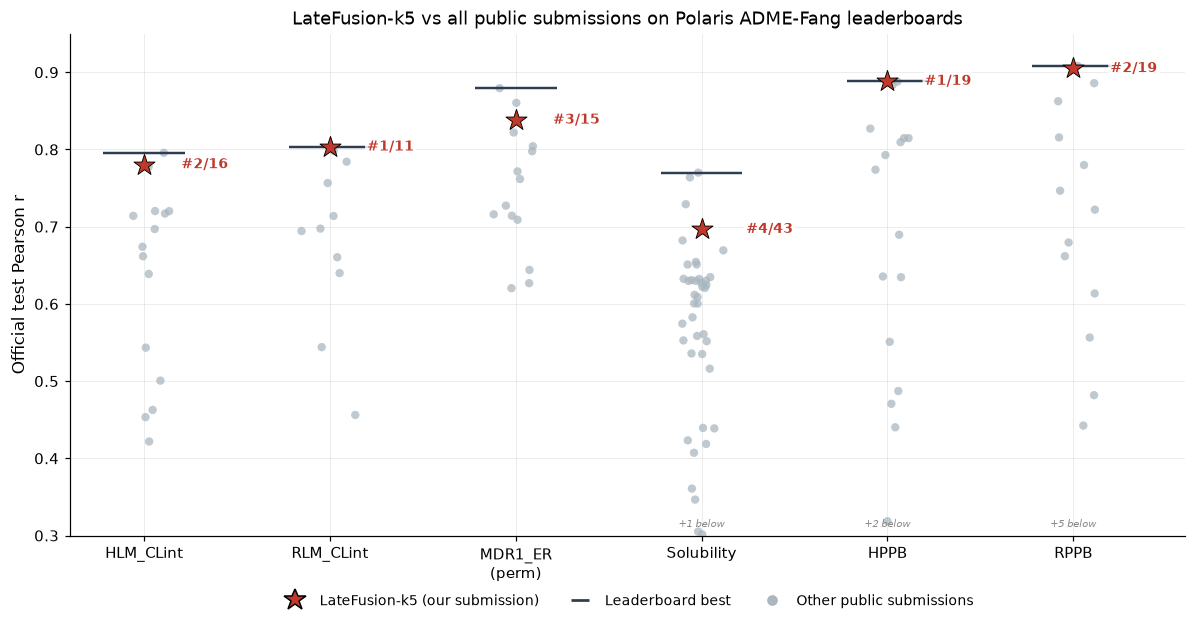

In [7]:
full = load_json("polaris_leaderboard_full.json")   # {key: [[name, pearson],...]}
order  = ["hclint","rclint","perm","solu","hppb","rppb"]
labmap = {"hclint":"HLM_CLint","rclint":"RLM_CLint","perm":"MDR1_ER\n(perm)",
          "solu":"Solubility","hppb":"HPPB","rppb":"RPPB"}
YLO, YHI = 0.3, 0.95
np.random.seed(0)

fig, ax = plt.subplots(figsize=(11, 5.8))
for i, key in enumerate(order):
    entries = full[key]
    others  = [(n,p) for n,p in entries if n!="LateFusion-k5"]
    our     = [p for n,p in entries if n=="LateFusion-k5"][0]
    ordered = sorted(entries, key=lambda x:-x[1])
    rank    = [j+1 for j,(n,p) in enumerate(ordered) if n=="LateFusion-k5"][0]
    total   = len(entries)
    ys=[p for _,p in others]; xs=np.random.normal(i,0.06,size=len(ys))
    ax.scatter(xs, ys, s=30, color=GREY, alpha=0.75, edgecolor="none", zorder=2)
    ax.hlines(max(p for _,p in entries), i-0.22, i+0.22, color=DARK, lw=1.6, zorder=3)
    ax.scatter([i],[our], s=210, marker="*", color=RED, edgecolor="black", lw=0.6, zorder=6)
    dx = 0.20 if key!="solu" else 0.24
    ax.text(i+dx, our, f"#{rank}/{total}", ha="left", va="center", fontsize=9,
            color=RED, fontweight="bold", zorder=7,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    nb=sum(1 for _,p in entries if p<YLO)
    if nb: ax.text(i, YLO+0.008, f"+{nb} below", ha="center", va="bottom",
                   fontsize=6.5, color="#8a8a8a", style="italic", zorder=4)
ax.set_xticks(range(len(order))); ax.set_xticklabels([labmap[k] for k in order])
ax.set_ylabel("Official test Pearson r"); ax.set_ylim(YLO,YHI); ax.set_xlim(-0.4,5.6)
ax.set_title("LateFusion-k5 vs all public submissions on Polaris ADME-Fang leaderboards")
leg=[Line2D([0],[0],marker="*",color="w",markerfacecolor=RED,markeredgecolor="black",markersize=15,label="LateFusion-k5 (our submission)"),
     Line2D([0],[0],marker="_",color=DARK,markersize=12,markeredgewidth=1.8,label="Leaderboard best",linestyle="None"),
     Line2D([0],[0],marker="o",color="w",markerfacecolor=GREY,markersize=8,label="Other public submissions")]
ax.legend(handles=leg, frameon=False, loc="lower center", ncol=3, bbox_to_anchor=(0.5,-0.17))
fig.tight_layout(); fig.savefig(f"{OUT}/figure6.png"); plt.show()
print("Figure 6 ranks:", {k:[j+1 for j,(n,p) in enumerate(sorted(full[k],key=lambda x:-x[1])) if n=="LateFusion-k5"][0] for k in order})

All six figures written to `../figures/`.